## Calculus and vector fields

Numerical calculus: integrals by adaptive quadrature, derivatives by finite differences, roots and minima, and the differential operators of vector calculus on a grid.

### Integrals

`integral` refines its subintervals until the error estimate is below the tolerance, so it handles peaks and infinite limits. `trapz` integrates sampled data. $\int_0^\infty e^{-x^2}\,dx = \sqrt{\pi}/2$.

In [ ]:
gauss = integral(@(x) exp(-x.^2), 0, Inf);
fprintf('integral %.15f, exact %.15f\n', gauss, sqrt(pi)/2)
peaky = integral(@(x) 1 ./ ((x - 0.3).^2 + 0.001), 0, 1)
xs = linspace(0, pi, 101);
by_trapz = trapz(xs, sin(xs))

integral 0.886226925452758, exact 0.886226925452758



peaky =

   94.5972


by_trapz =

    1.9998



### A running integral and derivatives

`cumtrapz` gives the integral up to each point; `gradient` differentiates sampled values by central differences, and `diff` gives successive differences.


max_error_derivative =

   1.3004e-04



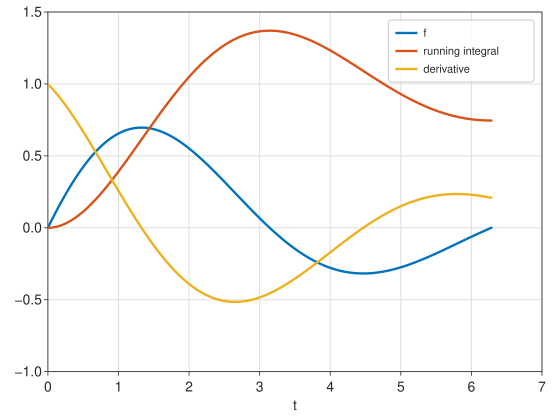

In [ ]:
figure
t = linspace(0, 2*pi, 200);
f = sin(t) .* exp(-t/4);
F = cumtrapz(t, f);
df = gradient(f, t(2) - t(1));
plot(t, f, t, F, t, df, 'LineWidth', 1.2)
legend('f', 'running integral', 'derivative'), xlabel('t')
grid on
max_error_derivative = max(abs(df(2:end-1) - (cos(t(2:end-1)) - sin(t(2:end-1))/4) .* exp(-t(2:end-1)/4)))

### Roots and minima

`fzero` finds a root of a function of one variable in a bracket; `fminsearch` minimizes a function of several variables without derivatives (Nelder-Mead). Rosenbrock's banana-shaped valley has its minimum at $(1, 1)$.

In [ ]:
root = fzero(@(x) cos(x) - x, [0 1])
rosen = @(v) 100*(v(2) - v(1)^2)^2 + (1 - v(1))^2;
[vmin, fmin] = fminsearch(rosen, [-1.2, 1])


root =

    0.7391




vmin =

    1.0000    1.0000


fmin =

   8.1777e-10



### Gradient, divergence and curl

On a grid, `gradient` of a scalar field gives a vector field. The divergence $\partial u/\partial x + \partial v/\partial y$ and the curl $\partial v/\partial x - \partial u/\partial y$, both from `gradient` here, measure how a vector field spreads out and how it turns. The field $(-y, x)$ is a pure rotation: divergence 0 and curl 2 everywhere.

rotation: divergence 0, curl 2


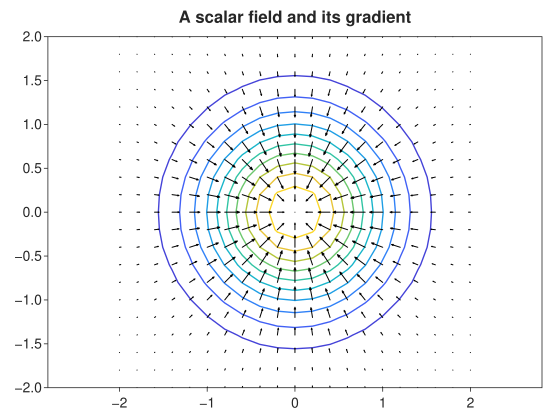

In [ ]:
figure
[gx, gy] = meshgrid(linspace(-2, 2, 21));
phi = exp(-(gx.^2 + gy.^2));
h0 = gx(1, 2) - gx(1, 1);
[px, py] = gradient(phi, h0);
contour(gx, gy, phi, 10), hold on
quiver(gx, gy, px, py, 'k'), hold off
axis equal, title('A scalar field and its gradient')
u = -gy; v = gx;
[ux, uy] = gradient(u, h0); [vx, vy] = gradient(v, h0);
div = ux + vy;
cz = vx - uy;
fprintf('rotation: divergence %g, curl %g\n', max(abs(div(:))), mean(cz(:)))

### The Laplacian

`del2` is the discrete Laplacian divided by 4 in two dimensions. For $x^2 + y^2$ the Laplacian is 4, so `4*del2` is 4 on the whole grid.

In [ ]:
bowl = gx.^2 + gy.^2;
lap = 4 * del2(bowl, h0);
fprintf('Laplacian between %.6f and %.6f\n', min(lap(:)), max(lap(:)))

Laplacian between 4.000000 and 4.000000


*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*